# ⚖️ Perbandingan Metode Klasifikasi

**Nama :** Fadhli Ilham Nafi'an Yuswono (23.18.001)
**Jurusan :** Teknik Informatika S-1 — Institut Teknologi Nasional Malang
**Penelitian :** Nafinder — Rekomendasi Kafe WFC Kota Malang dengan Multinomial Naive Bayes

**Metode yang dibandingkan :** Multinomial Naive Bayes, Complement Naive Bayes, Logistic Regression, LinearSVC
**Input :** `dataset_preprocessed.csv` (hasil notebook preprocessing)
**Output :** `perbandingan_metode.csv` dan `perbandingan_metode.png`

Semua metode memakai **split dan TF-IDF yang sama**, jadi perbedaan metrik benar-benar berasal dari perbedaan metode.


## ⚙️ IMPORT LIBRARY & SETUP ENVIRONMENT

In [1]:
import json
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

def ribu(n):
    """Format angka gaya Indonesia: 109.778"""
    return f"{n:,}".replace(",", ".")

def simpan(fig, nama):
    """Simpan dan unduh grafik di sel yang sama."""
    fig.savefig(nama, bbox_inches="tight")
    try:
        files.download(nama)
    except Exception as e:
        print("Download dilewati (bukan Colab):", e)

KOL_GRUP = "review_id"
KOL_TEKS = "teks_preprocessed"
KOL_ASPEK = "aspek"
KOL_LABEL = "sentimen"

print("✅ Libraries imported successfully!")


✅ Libraries imported successfully!


## 📥 LOAD DATASET

In [2]:
uploaded = files.upload()
nama = list(uploaded.keys())[0]
assert nama == "dataset_preprocessed.csv", f"Upload dataset_preprocessed.csv, bukan {nama!r}"
df = pd.read_csv(nama, encoding="utf-8-sig")

for k in ["review_id", "sub_kalimat", "aspek", "sentimen", "teks_preprocessed", "kafe_id"]:
    assert k in df.columns, f"Kolom wajib {k!r} tidak ditemukan"

print(f"✅ Dataset loaded successfully!")
print(f"📊 Data: {len(df):,} label | {df['review_id'].nunique():,} review unik | {df['kafe_id'].nunique()} kafe")


Saving dataset_preprocessed.csv to dataset_preprocessed.csv
✅ Dataset loaded successfully!
📊 Data: 240,636 label | 88,189 review unik | 323 kafe


## ✂️ PERSIAPAN SPLIT & TF-IDF

Split anti-bocor per `review_id` dan TF-IDF dibuat sekali di sini, lalu dipakai oleh semua metode supaya perbandingannya adil.


In [3]:
!pip install -q imbalanced-learn
import time
from collections import Counter
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score

RASIO_TEST = 0.2
RANDOM_STATE = 42

# Hapus observasi duplikat dulu
df = df.drop_duplicates(
    subset=[KOL_GRUP, KOL_TEKS, KOL_ASPEK, KOL_LABEL]
).reset_index(drop=True)

# Satu review_id hanya dialokasikan ke satu sisi
splitter = GroupShuffleSplit(n_splits=1, test_size=RASIO_TEST, random_state=RANDOM_STATE)
idx_train, idx_test = next(splitter.split(df, groups=df[KOL_GRUP]))
train = df.iloc[idx_train].reset_index(drop=True)
test = df.iloc[idx_test].reset_index(drop=True)

# Singkirkan dari testing teks yang juga terdapat pada training
teks_latih = set(train[KOL_TEKS])
test = test[~test[KOL_TEKS].isin(teks_latih)].reset_index(drop=True)

assert set(train[KOL_GRUP]).isdisjoint(set(test[KOL_GRUP])), "Review bocor antar split"
assert set(train[KOL_TEKS]).isdisjoint(set(test[KOL_TEKS])), "Teks bocor antar split"

# TF-IDF dibuat sekali, dipakai semua metode
tfidf = TfidfVectorizer(lowercase=True, sublinear_tf=True, smooth_idf=True,
                        token_pattern=r"(?u)\b\w\w+\b")
X_train = tfidf.fit_transform(train[KOL_TEKS])
X_test = tfidf.transform(test[KOL_TEKS])

print(f"📊 Data training : {ribu(len(train))} label | {train[KOL_GRUP].nunique():,} review")
print(f"📊 Data testing  : {ribu(len(test))} label | {test[KOL_GRUP].nunique():,} review")
print(f"📊 Matriks TF-IDF: training {X_train.shape} | testing {X_test.shape}")
print("✅ Validasi anti-bocor per review_id dan teks: lolos")


📊 Data training : 192.341 label | 70,551 review
📊 Data testing  : 37.548 label | 14,930 review
📊 Matriks TF-IDF: training (192341, 25761) | testing (37548, 25761)
✅ Validasi anti-bocor per review_id dan teks: lolos


## 🏋️ LATIH & BANDINGKAN SEMUA METODE

Setiap metode dilatih pada TF-IDF yang sama; ROS hanya diterapkan pada training set (fitur asli testing tidak pernah diubah). Waktu pelatihan dicatat untuk tiap metode.


In [4]:
# Cache hasil ROS supaya tidak diulang tiap metode
_cache = {}

def fitur(pakai_ros):
    if pakai_ros not in _cache:
        if pakai_ros:
            ros = RandomOverSampler(random_state=RANDOM_STATE)
            Xr, yr = ros.fit_resample(X_train, train[KOL_LABEL].values)
        else:
            Xr, yr = X_train, train[KOL_LABEL].values
        _cache[pakai_ros] = (Xr, yr)
    return _cache[pakai_ros]

konfigurasi = [
    ("MNB (ROS)",                MultinomialNB(alpha=1.0), True),
    ("MNB (tanpa ROS)",          MultinomialNB(alpha=1.0), False),
    ("ComplementNB (ROS)",       ComplementNB(alpha=1.0), True),
    ("ComplementNB (tanpa ROS)", ComplementNB(alpha=1.0), False),
    ("LogisticRegression (ROS)", LogisticRegression(max_iter=2000), True),
    ("LogisticRegression (tanpa ROS)", LogisticRegression(max_iter=2000), False),
    ("LinearSVC (ROS)",          LinearSVC(), True),
    ("LinearSVC (tanpa ROS)",    LinearSVC(), False),
]

baris = []
for nama, model, pakai_ros in konfigurasi:
    Xtr, ytr = fitur(pakai_ros)
    t0 = time.time()
    model.fit(Xtr, ytr)
    y_pred_model = model.predict(X_test)
    dt = time.time() - t0
    rep = classification_report(test[KOL_LABEL], y_pred_model, output_dict=True, zero_division=0)
    baris.append({
        "metode": nama,
        "accuracy": round(rep["accuracy"], 4),
        "f1_macro": round(rep["macro avg"]["f1-score"], 4),
        "f1_negatif": round(rep["negatif"]["f1-score"], 4),
        "f1_netral": round(rep["netral"]["f1-score"], 4),
        "f1_positif": round(rep["positif"]["f1-score"], 4),
        "latih_detik": round(dt, 2),
    })
    print(f"{nama:32} acc={rep['accuracy']*100:5.2f}%  macroF1={rep['macro avg']['f1-score']:.4f}  ({dt:.1f}s)")

tabel = pd.DataFrame(baris).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(tabel)


MNB (ROS)                        acc=69.83%  macroF1=0.5566  (6.2s)
MNB (tanpa ROS)                  acc=81.72%  macroF1=0.4345  (2.2s)
ComplementNB (ROS)               acc=72.71%  macroF1=0.5669  (9.1s)
ComplementNB (tanpa ROS)         acc=77.27%  macroF1=0.5773  (2.9s)
LogisticRegression (ROS)         acc=75.94%  macroF1=0.6245  (64.1s)
LogisticRegression (tanpa ROS)   acc=84.77%  macroF1=0.6196  (16.7s)
LinearSVC (ROS)                  acc=75.12%  macroF1=0.6103  (70.5s)
LinearSVC (tanpa ROS)            acc=83.97%  macroF1=0.6003  (9.3s)


,metode,accuracy,f1_macro,f1_negatif,f1_netral,f1_positif,latih_detik
0,LogisticRegression (ROS),0.7594,0.6245,0.5959,0.4120,0.8655,64.09
1,LogisticRegression (tanpa ROS),0.8477,0.6196,0.6211,0.3151,0.9224,16.66
2,LinearSVC (ROS),0.7512,0.6103,0.5739,0.3984,0.8586,70.52
3,LinearSVC (tanpa ROS),0.8397,0.6003,0.6093,0.2737,0.9179,9.29
4,ComplementNB (tanpa ROS),0.7727,0.5773,0.5385,0.3153,0.8782,2.87
5,ComplementNB (ROS),0.7271,0.5669,0.5214,0.3361,0.8433,9.12
6,MNB (ROS),0.6983,0.5566,0.5157,0.3326,0.8213,6.23
7,MNB (tanpa ROS),0.8172,0.4345,0.3809,0.0227,0.8999,2.20


### 📊 PERBANDINGAN ACCURACY & MACRO F1 ANTAR METODE

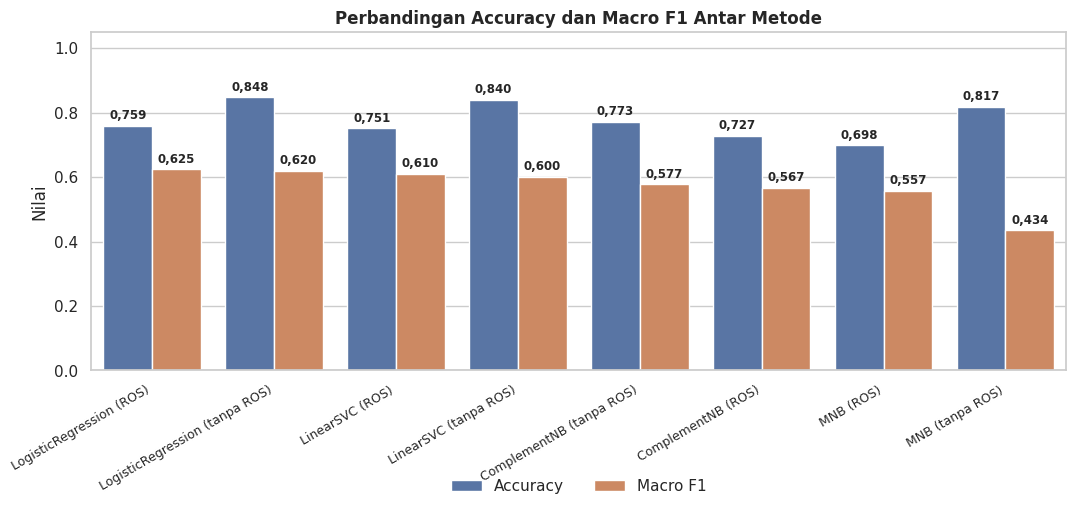

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
plot_df = tabel.melt(id_vars=["metode"], value_vars=["accuracy", "f1_macro"],
                     var_name="Metrik", value_name="Nilai")
plot_df["Metrik"] = plot_df["Metrik"].map({"accuracy": "Accuracy", "f1_macro": "Macro F1"})

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=plot_df, x="metode", y="Nilai", hue="Metrik", ax=ax)
for b in ax.patches:
    h = b.get_height()
    if h > 0:
        ax.text(b.get_x() + b.get_width()/2, h + 0.012, f"{h:.3f}".replace(".", ","),
                ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Nilai")
ax.set_xlabel("")
ax.set_title("Perbandingan Accuracy dan Macro F1 Antar Metode", fontweight="bold")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.28))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
simpan(fig, "perbandingan_metode.png")


## 📊 RINGKASAN & RUJUKAN

In [6]:
tabel.to_csv("perbandingan_metode.csv", index=False)
print("✅ Tersimpan: perbandingan_metode.csv")
files.download("perbandingan_metode.csv")

print("\n🏆 Urutan berdasarkan f1_macro:")
display(tabel)

print("\n📏 Rujukan majority baseline (tebak kelas terbesar terus):")
kelas_terbesar = train[KOL_LABEL].value_counts().idxmax()
r0 = classification_report(test[KOL_LABEL], [kelas_terbesar] * len(test),
                           output_dict=True, zero_division=0)
print(f"   accuracy={r0['accuracy']*100:.2f}%  f1_macro={r0['macro avg']['f1-score']:.4f}")


✅ Tersimpan: perbandingan_metode.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🏆 Urutan berdasarkan f1_macro:


,metode,accuracy,f1_macro,f1_negatif,f1_netral,f1_positif,latih_detik
0,LogisticRegression (ROS),0.7594,0.6245,0.5959,0.4120,0.8655,64.09
1,LogisticRegression (tanpa ROS),0.8477,0.6196,0.6211,0.3151,0.9224,16.66
2,LinearSVC (ROS),0.7512,0.6103,0.5739,0.3984,0.8586,70.52
3,LinearSVC (tanpa ROS),0.8397,0.6003,0.6093,0.2737,0.9179,9.29
4,ComplementNB (tanpa ROS),0.7727,0.5773,0.5385,0.3153,0.8782,2.87
5,ComplementNB (ROS),0.7271,0.5669,0.5214,0.3361,0.8433,9.12
6,MNB (ROS),0.6983,0.5566,0.5157,0.3326,0.8213,6.23
7,MNB (tanpa ROS),0.8172,0.4345,0.3809,0.0227,0.8999,2.20



📏 Rujukan majority baseline (tebak kelas terbesar terus):
   accuracy=79.58%  f1_macro=0.2954
